# Publication figures: Viasat penetration comparison

This notebook regenerates the central validation figures for the revised article from the tabular outputs produced by `viasat_analysis.py`. It replaces separate, low-resolution panels with compact comparisons designed for print.

**Inputs**

- `article/results/2020/global/penetrazione/log_eta_20200210_20200217.txt`
- `article/results/2021/global/penetrazione/log_eta_20210628_20210704.txt`

**Outputs**

- `article/results/figures/viasat_distribution.{pdf,png}`
- `article/results/figures/viasat_ecdf_ks.{pdf,png}`
- `article/results/figures/viasat_decade_shares.{pdf,png}`
- `article/results/figures/viasat_summary_statistics.csv`
- `article/results/figures/viasat_decade_summary.csv`


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ks_2samp


def find_project_root() -> Path:
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / 'article' / 'results').is_dir():
            return candidate
    raise FileNotFoundError('Run this notebook from inside the covid_hep repository.')


PROJECT = find_project_root()
RESULTS = PROJECT / 'article' / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

PALETTE = {'2020': '#0072B2', '2021': '#D55E00'}
sns.set_theme(context='talk', style='ticks', font_scale=1.25, palette=PALETTE.values())
plt.rcParams.update({'font.size': 18, 'axes.titlesize': 22, 'axes.labelsize': 19, 'xtick.labelsize': 16, 'ytick.labelsize': 16, 'legend.fontsize': 16, 'legend.title_fontsize': 16, 'figure.dpi': 120, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})


def save_figure(fig: plt.Figure, stem: str) -> None:
    for extension in ('pdf', 'png'):
        fig.savefig(FIGURES / f'{stem}.{extension}', bbox_inches='tight', facecolor='white')


PROJECT, FIGURES


(PosixPath('/mnt/c/Users/belli/OneDrive/Desktop/code/covid_hep'),
 PosixPath('/mnt/c/Users/belli/OneDrive/Desktop/code/covid_hep/article/results/figures'))

In [2]:
input_files = {
    '2020': RESULTS / '2020/global/penetrazione/log_eta_20200210_20200217.txt',
    '2021': RESULTS / '2021/global/penetrazione/log_eta_20210628_20210704.txt',
}

frames = []
for year, path in input_files.items():
    values = pd.read_csv(path, header=None, names=['log_eta'])
    values['year'] = year
    values['eta_percent'] = 100 * 10 ** values['log_eta']
    rounded = np.rint(values['log_eta']).astype(int)
    values['decade'] = rounded.where(rounded.isin([-1, -2, -3]), 99).map(
        {-1: r'$10^{-1}$', -2: r'$10^{-2}$', -3: r'$10^{-3}$', 99: 'other'}
    )
    frames.append(values)

penetration = pd.concat(frames, ignore_index=True)
ks = ks_2samp(
    penetration.loc[penetration['year'] == '2020', 'log_eta'],
    penetration.loc[penetration['year'] == '2021', 'log_eta'],
)

summary = penetration.groupby('year').agg(
    segments=('log_eta', 'size'),
    median_log_eta=('log_eta', 'median'),
    median_eta_percent=('eta_percent', 'median'),
    mean_eta_percent=('eta_percent', 'mean'),
)
summary['ks_D'] = ks.statistic
summary['ks_pvalue'] = ks.pvalue
summary.to_csv(FIGURES / 'viasat_summary_statistics.csv')

decade_summary = penetration.loc[penetration['decade'] == r'$10^{-1}$'].groupby('year').agg(
    segments=('eta_percent', 'size'),
    median_eta_percent=('eta_percent', 'median'),
    q25_eta_percent=('eta_percent', lambda x: x.quantile(0.25)),
    q75_eta_percent=('eta_percent', lambda x: x.quantile(0.75)),
    mean_eta_percent=('eta_percent', 'mean'),
    std_eta_percent=('eta_percent', 'std'),
)
decade_summary.to_csv(FIGURES / 'viasat_decade_summary.csv')
summary.round(4), decade_summary.round(3)


(      segments  median_log_eta  median_eta_percent  mean_eta_percent    ks_D  \
 year                                                                           
 2020       848         -1.3962              4.0164            6.2770  0.1085   
 2021       845         -1.5161              3.0472            4.6864  0.1085   
 
       ks_pvalue  
 year             
 2020     0.0001  
 2021     0.0001  ,
       segments  median_eta_percent  q25_eta_percent  q75_eta_percent  \
 year                                                                   
 2020       480               7.785            5.100           12.397   
 2021       411               6.666            4.536           10.249   
 
       mean_eta_percent  std_eta_percent  
 year                                     
 2020             9.534            5.736  
 2021             8.094            4.553  )

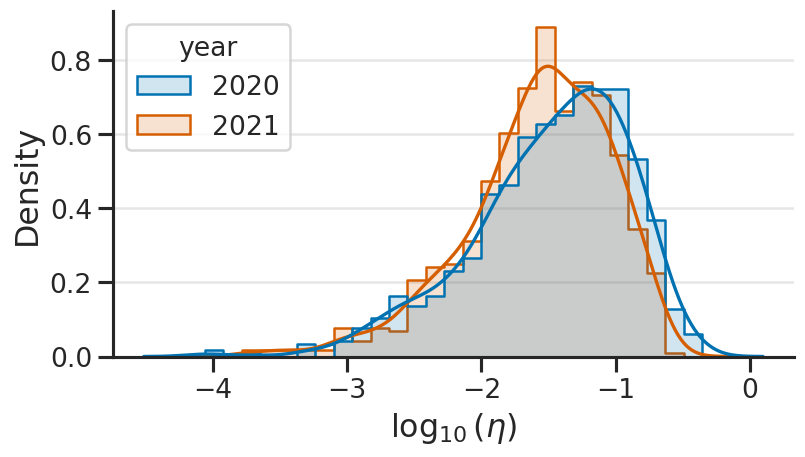

In [3]:
fig, ax = plt.subplots(figsize=(6.6, 3.7), constrained_layout=True)
bins = np.linspace(penetration['log_eta'].min(), penetration['log_eta'].max(), 28)
sns.histplot(
    data=penetration, x='log_eta', hue='year', hue_order=['2020', '2021'],
    bins=bins, stat='density', common_norm=False, element='step', fill=True,
    alpha=0.18, palette=PALETTE, ax=ax,
)
sns.kdeplot(
    data=penetration, x='log_eta', hue='year', hue_order=['2020', '2021'],
    common_norm=False, palette=PALETTE, linewidth=2, legend=False, ax=ax,
)
ax.set(xlabel=r'$\log_{10}(\eta)$', ylabel='Density')
ax.grid(axis='y', color='0.9')
sns.despine(ax=ax)
save_figure(fig, 'viasat_distribution')
plt.show()


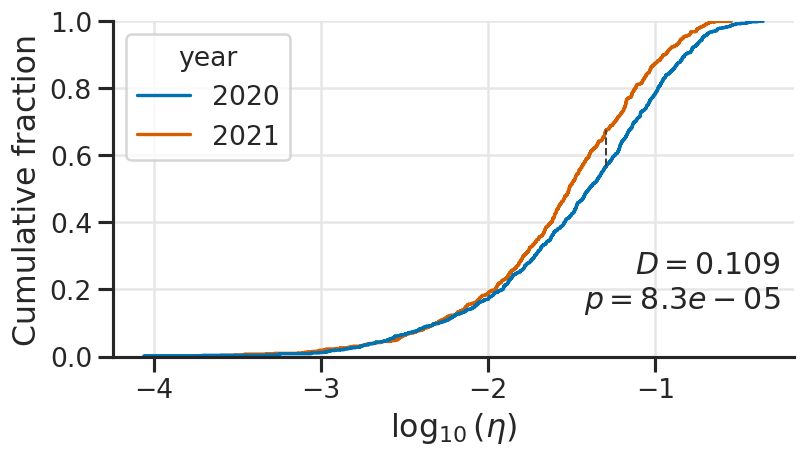

In [4]:
fig, ax = plt.subplots(figsize=(6.6, 3.7), constrained_layout=True)
sns.ecdfplot(
    data=penetration, x='log_eta', hue='year', hue_order=['2020', '2021'],
    palette=PALETTE, linewidth=2, ax=ax,
)
x20 = np.sort(penetration.loc[penetration['year'] == '2020', 'log_eta'].to_numpy())
x21 = np.sort(penetration.loc[penetration['year'] == '2021', 'log_eta'].to_numpy())
grid = np.sort(np.concatenate([x20, x21]))
f20 = np.searchsorted(x20, grid, side='right') / len(x20)
f21 = np.searchsorted(x21, grid, side='right') / len(x21)
idx = np.argmax(np.abs(f20 - f21))
ax.vlines(grid[idx], min(f20[idx], f21[idx]), max(f20[idx], f21[idx]), color='0.25', ls='--', lw=1.2)
ax.text(0.98, 0.12, rf'$D={ks.statistic:.3f}$' + '\n' + rf'$p={ks.pvalue:.2g}$', transform=ax.transAxes, ha='right', va='bottom')
ax.set(xlabel=r'$\log_{10}(\eta)$', ylabel='Cumulative fraction')
ax.grid(axis='both', color='0.9')
sns.despine(ax=ax)
save_figure(fig, 'viasat_ecdf_ks')
plt.show()


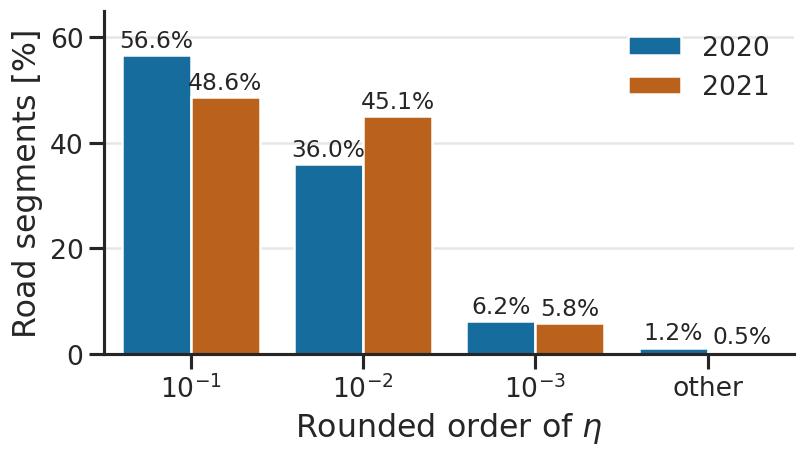

,year,decade,share
0,2020,$10^{-1}$,56.60
4,2021,$10^{-1}$,48.64
1,2020,$10^{-2}$,35.97
5,2021,$10^{-2}$,45.09
2,2020,$10^{-3}$,6.25
6,2021,$10^{-3}$,5.80
3,2020,other,1.18
7,2021,other,0.47


In [5]:
order = [r'$10^{-1}$', r'$10^{-2}$', r'$10^{-3}$', 'other']
shares = (
    penetration.groupby(['year', 'decade'], observed=False).size()
    .groupby(level=0).transform(lambda count: 100 * count / count.sum())
    .rename('share').reset_index()
)
shares['decade'] = pd.Categorical(shares['decade'], order, ordered=True)

fig, ax = plt.subplots(figsize=(6.6, 3.7), constrained_layout=True)
sns.barplot(
    data=shares, x='decade', y='share', hue='year', hue_order=['2020', '2021'],
    palette=PALETTE, ax=ax,
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2, fontsize=14)
ax.set(xlabel=r'Rounded order of $\eta$', ylabel='Road segments [%]', ylim=(0, 65))
ax.legend(title=None, frameon=False)
ax.grid(axis='y', color='0.9')
sns.despine(ax=ax)
save_figure(fig, 'viasat_decade_shares')
plt.show()

shares.sort_values(['decade', 'year']).round(2)
